Ex 1 Question 3 part 3

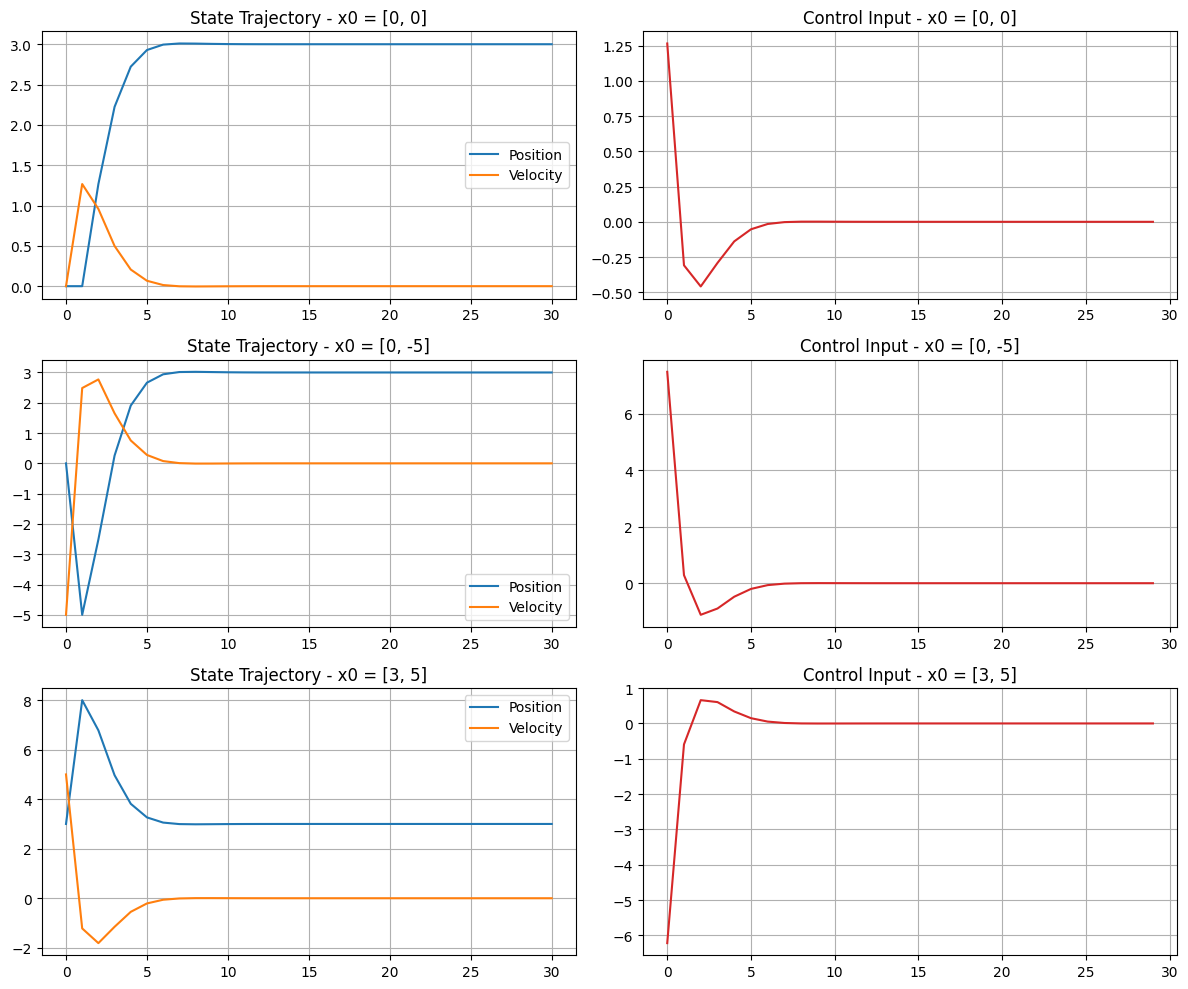

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_discrete_are

# System matrices
A = np.array([[1, 1],
              [0, 1]])
B = np.array([[0],
              [1]])

# cost matrices
Q = np.eye(2)
R = np.array([[1]])

# Reference state
x_ref = np.array([[3], [0]])


P = solve_discrete_are(A, B, Q, R)
K = np.linalg.inv(R + B.T @ P @ B) @ (B.T @ P @ A)

# simulation parameters
T = 30  # number of time samples
initial_conditions = {
    'x0 = [0, 0]': np.array([[0], [0]]),
    'x0 = [0, -5]': np.array([[0], [-5]]),
    'x0 = [3, 5]': np.array([[3], [5]])
}

# plot
fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for i, (label, x0) in enumerate(initial_conditions.items()):
    x = x0.copy()
    x_hist = [x.flatten()]
    u_hist = []

    for t in range(T):
        x_tilde = x - x_ref
        u = -K @ x_tilde
        x = A @ x + B @ u
        x_hist.append(x.flatten())
        u_hist.append(u.item())

    x_hist = np.array(x_hist)
    u_hist = np.array(u_hist)

    axes[i, 0].plot(x_hist[:, 0], label='Position')
    axes[i, 0].plot(x_hist[:, 1], label='Velocity')
    axes[i, 0].set_title(f"State Trajectory - {label}")
    axes[i, 0].legend()
    axes[i, 0].grid(True)

    axes[i, 1].plot(u_hist, label='Control Input', color='tab:red')
    axes[i, 1].set_title(f"Control Input - {label}")
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()


Ex 1 Question 3 part 4


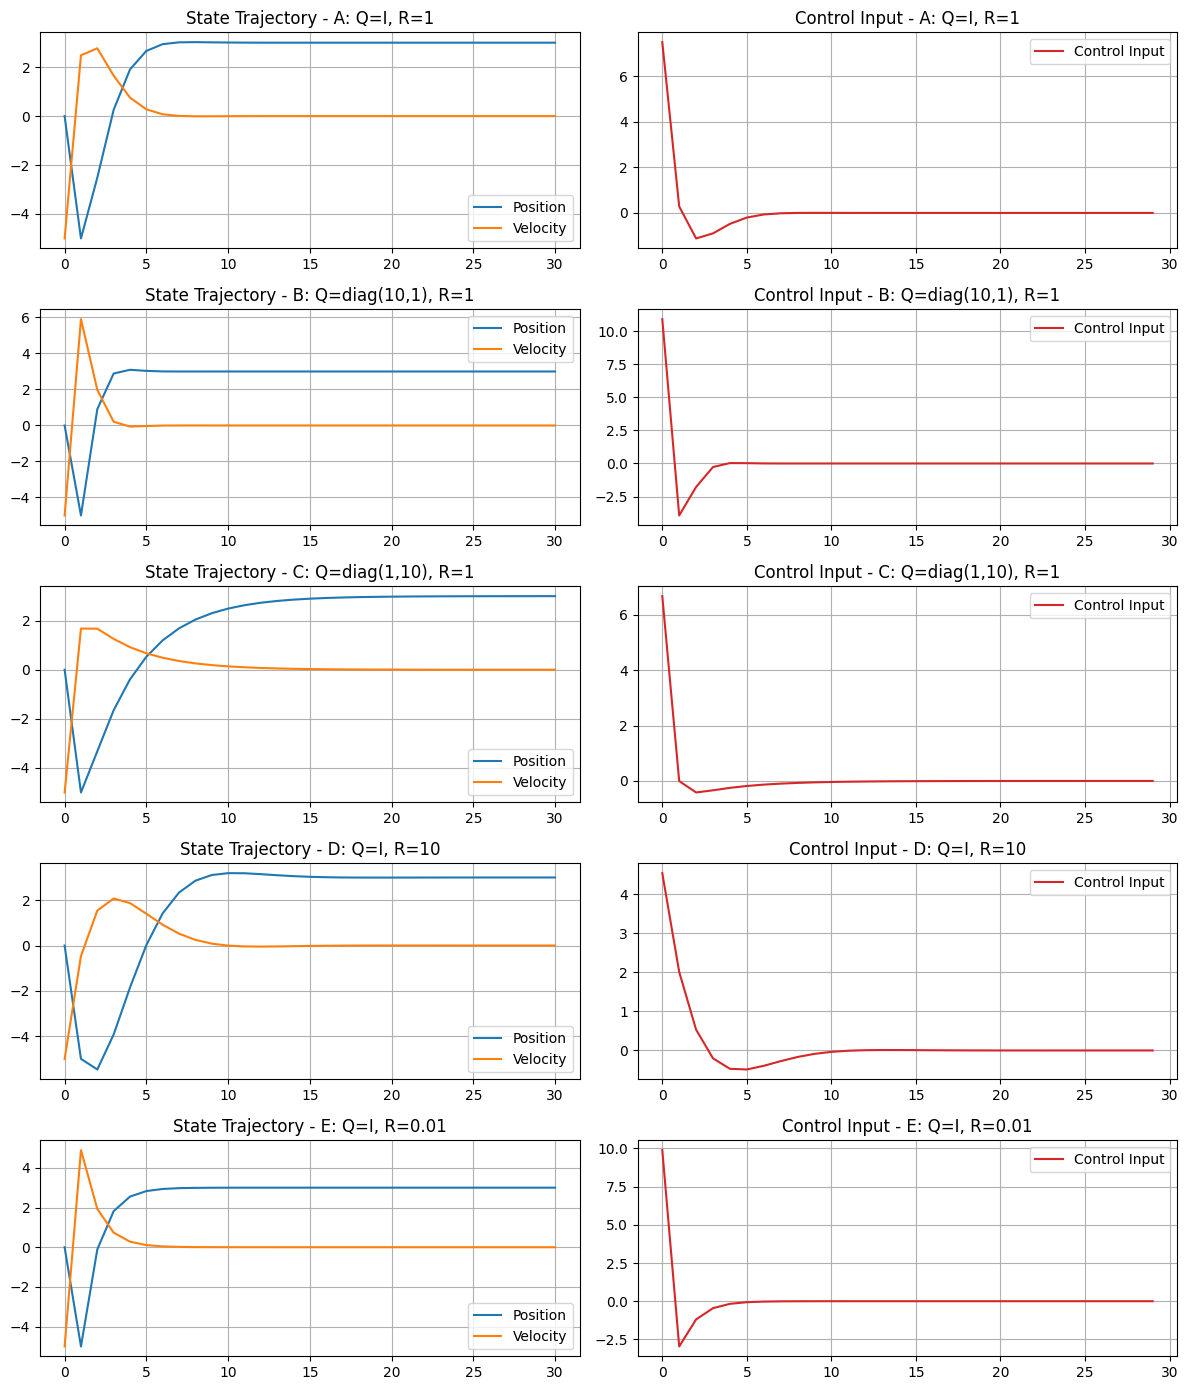

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_discrete_are

# System matrices
A = np.array([[1, 1],
              [0, 1]])
B = np.array([[0],
              [1]])
x_ref = np.array([[3], [0]])
x0 = np.array([[0], [-5]])
T = 30

# different Q and R matrices
cost_settings = {
    "A: Q=I, R=1": (np.eye(2), np.array([[1]])),
    "B: Q=diag(10,1), R=1": (np.diag([10, 1]), np.array([[1]])),
    "C: Q=diag(1,10), R=1": (np.diag([1, 10]), np.array([[1]])),
    "D: Q=I, R=10": (np.eye(2), np.array([[10]])),
    "E: Q=I, R=0.01": (np.eye(2), np.array([[0.01]])),
}

# subplots
fig, axes = plt.subplots(len(cost_settings), 2, figsize=(12, 14))

for i, (label, (Q, R)) in enumerate(cost_settings.items()):
    #  Riccati equation
    P = solve_discrete_are(A, B, Q, R)
    K = np.linalg.inv(R + B.T @ P @ B) @ (B.T @ P @ A)


    x = x0.copy()
    x_hist = [x.flatten()]
    u_hist = []

    for t in range(T):
        x_tilde = x - x_ref
        u = -K @ x_tilde
        x = A @ x + B @ u
        x_hist.append(x.flatten())
        u_hist.append(u.item())

    x_hist = np.array(x_hist)
    u_hist = np.array(u_hist)

    #  state trajectory
    axes[i, 0].plot(x_hist[:, 0], label='Position')
    axes[i, 0].plot(x_hist[:, 1], label='Velocity')
    axes[i, 0].set_title(f"State Trajectory - {label}")
    axes[i, 0].legend()
    axes[i, 0].grid(True)

    # Plot control effort
    axes[i, 1].plot(u_hist, label='Control Input', color='tab:red')
    axes[i, 1].set_title(f"Control Input - {label}")
    axes[i, 1].legend()
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()
